# Breast Cancer Classification with Ensembles
Can combining several models beat the best single model? This notebook compares five base classifiers with three ways of combining them — **soft voting, blending and stacking** — on the Wisconsin Diagnostic Breast Cancer dataset.

**Data:** 569 tumours, 30 measurements of cell nuclei computed from a digitised fine-needle aspirate image.  
**Positive class:** malignant (scikit-learn encodes it as 0, so the target is flipped).  
**Metrics:** ROC-AUC, plus recall for the malignant class — missing a malignant tumour is the costly error.

*Educational project — not medical advice.*

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier, StackingClassifier
from sklearn.metrics import roc_auc_score, classification_report, ConfusionMatrixDisplay, RocCurveDisplay
sns.set_theme(style='whitegrid'); SEED = 42

## 1. Data

In [2]:
d = load_breast_cancer(as_frame=True)
X = d.data.copy(); X.columns = [c.replace(' ', '_') for c in X.columns]
y = (d.target == 0).astype(int)   # 1 = malignant
print(X.shape, '| missing values:', X.isna().sum().sum())
y.map({0: 'benign', 1: 'malignant'}).value_counts()

(569, 30) | missing values: 0


target
benign       357
malignant    212
Name: count, dtype: int64

Each of 10 nucleus properties (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension) is given three times: the **mean** over all nuclei, its **standard error**, and the **worst** (mean of the 3 largest) value. ~37% of tumours are malignant.

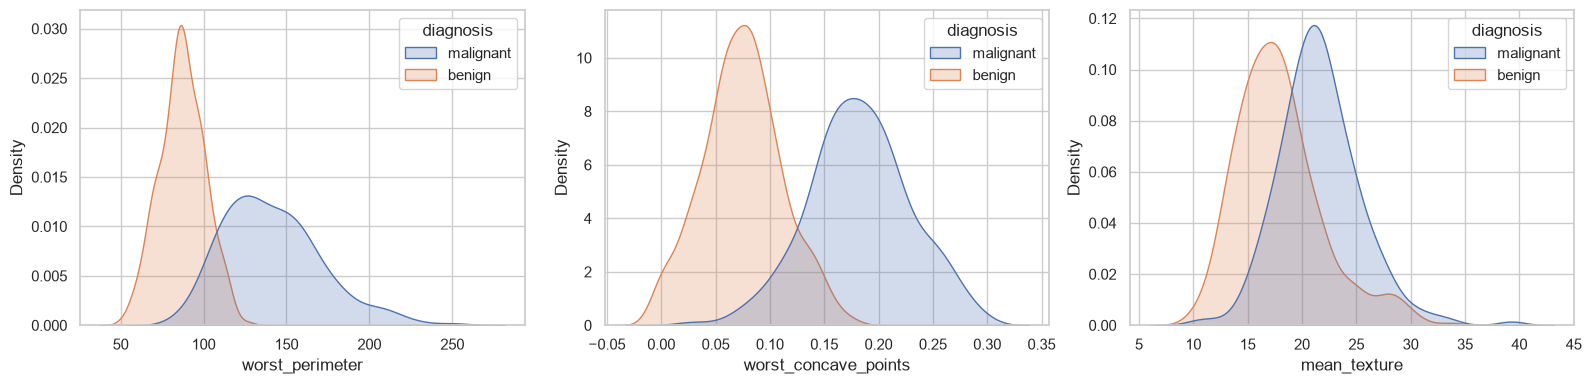

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['worst_perimeter', 'worst_concave_points', 'mean_texture']):
    sns.kdeplot(data=X.assign(diagnosis=y.map({0: 'benign', 1: 'malignant'})), x=col, hue='diagnosis',
                fill=True, common_norm=False, ax=ax)
plt.tight_layout()

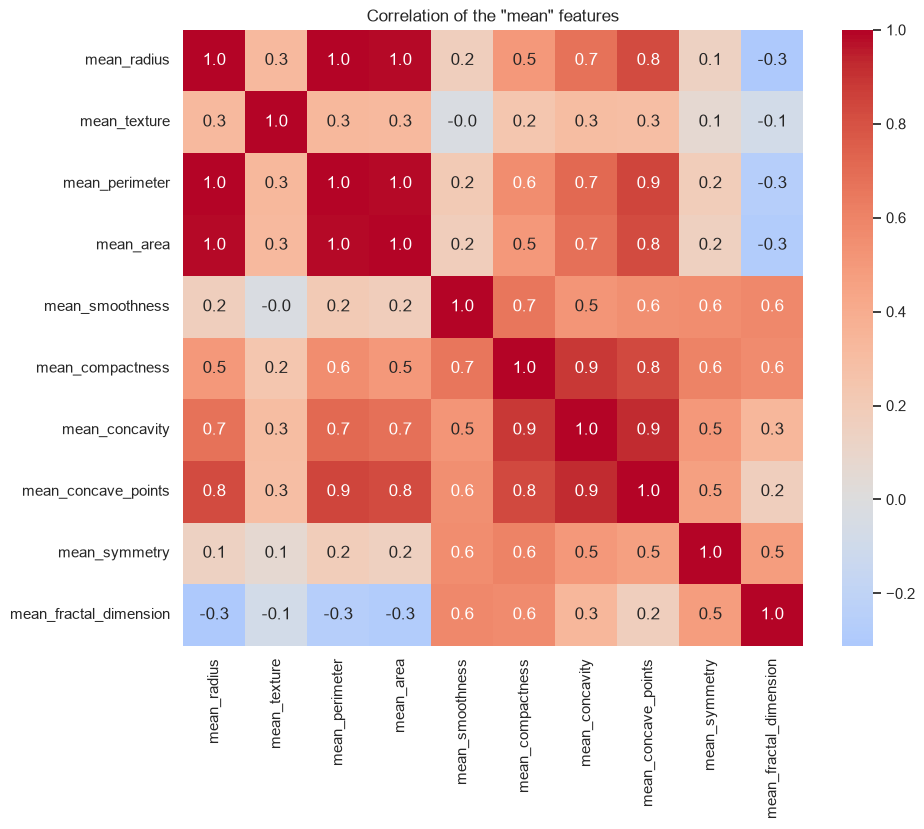

In [4]:
plt.figure(figsize=(10, 8))
sns.heatmap(X.filter(like='mean_').corr(), cmap='coolwarm', center=0, annot=True, fmt='.1f')
plt.title('Correlation of the "mean" features');

Size-related features (radius, perimeter, area) are almost perfectly correlated, and malignant tumours are clearly larger and more irregular (more concave points). The classes are well separated, so the interesting question is how close to perfect the models can get.

## 2. Train/test split
The test set (20%) is kept aside until the very end. All comparisons use 5-fold stratified CV repeated 3 times on the training set — with only 455 training rows a single CV run is noisy.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
print(X_train.shape, X_test.shape)

(455, 30) (114, 30)


## 3. Base models and ensembles
Five *diverse* base models: a linear model, a kernel method, a distance-based method and two tree ensembles. Everything starts with a `StandardScaler` (needed for LR, SVM and k-NN, harmless for trees).

- **Soft voting** — average the predicted probabilities.
- **Stacking** — a logistic regression learns how to combine the base models' *out-of-fold* probabilities (inner 5-fold CV).
- **Blending** — simpler variant: base models are trained on 75% of the training data and the combiner on the other 25%.

In [6]:
def base_estimators():
    return [
        ('lr', LogisticRegression(max_iter=5000)),
        ('svm', SVC(C=3.0, probability=True, random_state=SEED)),
        ('knn', KNeighborsClassifier(n_neighbors=9)),
        ('rf', RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=SEED)),
        ('gb', GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=2, random_state=SEED)),
    ]

class BlendingClassifier(ClassifierMixin, BaseEstimator):
    def __init__(self, estimators, holdout=0.25, random_state=None):
        self.estimators, self.holdout, self.random_state = estimators, holdout, random_state
    def fit(self, X, y):
        X_fit, X_hold, y_fit, y_hold = train_test_split(X, y, test_size=self.holdout, stratify=y, random_state=self.random_state)
        self.fitted_ = [clone(e).fit(X_fit, y_fit) for _, e in self.estimators]
        self.meta_ = LogisticRegression().fit(self._level1(X_hold), y_hold)
        self.classes_ = self.meta_.classes_
        return self
    def _level1(self, X):
        return np.column_stack([m.predict_proba(X)[:, 1] for m in self.fitted_])
    def predict_proba(self, X):
        return self.meta_.predict_proba(self._level1(X))
    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(1)]

names = {'lr': 'Logistic Regression', 'svm': 'SVM (RBF)', 'knn': 'k-NN', 'rf': 'Random Forest', 'gb': 'Gradient Boosting'}
def build_models():
    m = {names[k]: make_pipeline(StandardScaler(), e) for k, e in base_estimators()}
    m['Soft Voting'] = make_pipeline(StandardScaler(), VotingClassifier(base_estimators(), voting='soft'))
    m['Blending'] = make_pipeline(StandardScaler(), BlendingClassifier(base_estimators(), random_state=SEED))
    m['Stacking'] = make_pipeline(StandardScaler(), StackingClassifier(base_estimators(), final_estimator=LogisticRegression(),
                                  cv=StratifiedKFold(5, shuffle=True, random_state=SEED)))
    return m

def compare(X_tr):
    rows = []
    for name, model in build_models().items():
        r = cross_validate(model, X_tr, y_train, cv=cv, n_jobs=1, scoring=['roc_auc', 'f1', 'recall', 'accuracy'])
        rows.append({'model': name, **{k: r[f'test_{k}'].mean() for k in ['roc_auc', 'f1', 'recall', 'accuracy']},
                     'roc_auc_std': r['test_roc_auc'].std()})
    return pd.DataFrame(rows).set_index('model')

### All 30 features

In [7]:
res30 = compare(X_train)
res30.sort_values('roc_auc', ascending=False).round(4)

,roc_auc,f1,recall,accuracy,roc_auc_std
model,,,,,
Logistic Regression,0.9960,0.9672,0.9569,0.9758,0.0046
Stacking,0.9955,0.9743,0.9686,0.9810,0.0047
SVM (RBF),0.9954,0.9701,0.9588,0.9780,0.0045
Soft Voting,0.9948,0.9647,0.9490,0.9744,0.0049
Blending,0.9946,0.9631,0.9392,0.9736,0.0048
Random Forest,0.9893,0.9373,0.9275,0.9538,0.0074
Gradient Boosting,0.9883,0.9401,0.9314,0.9560,0.0096
k-NN,0.9864,0.9448,0.9059,0.9612,0.0145


All models are in the 0.98–0.997 ROC-AUC range. The linear models (LR, SVM) are already excellent; the ensembles land at the top together with them, while k-NN and the tree models are a little weaker on their own. Differences between the best approaches are smaller than one standard deviation across folds.

### Why ensembles help: diversity
Ensembles only help when the base models make *different* mistakes. Out-of-fold probabilities show how correlated the base models are:

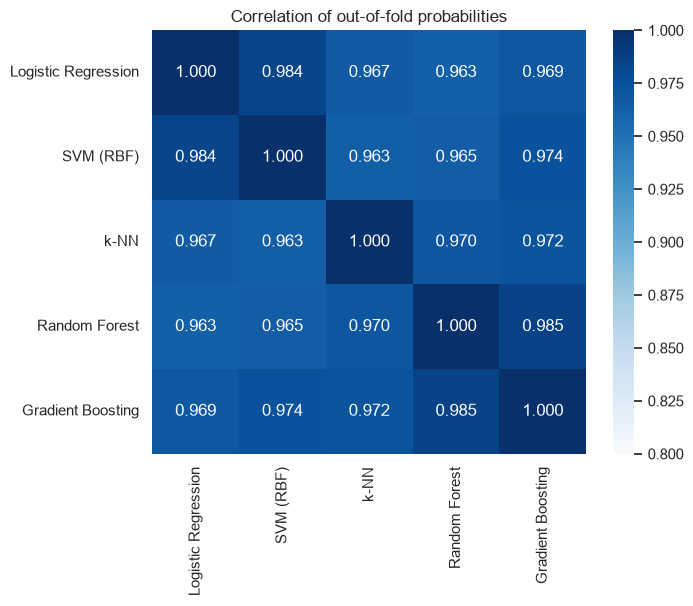

In [8]:
oof = pd.DataFrame({names[k]: cross_val_predict(make_pipeline(StandardScaler(), e), X_train, y_train,
                                                cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method='predict_proba')[:, 1]
                    for k, e in base_estimators()})
plt.figure(figsize=(7, 5.5))
sns.heatmap(oof.corr(), annot=True, fmt='.3f', cmap='Blues', vmin=0.8, vmax=1)
plt.title('Correlation of out-of-fold probabilities');

The models agree strongly (the task is easy), and the tree models differ most from the linear ones — that's the diversity the meta-model can exploit.

## 4. A 10-feature model for the web demo
A form with 30 inputs is unusable, and many features are redundant. Forward feature selection with logistic regression (on the training set only, scored by CV ROC-AUC) picks 10 complementary measurements:

In [9]:
sfs = SequentialFeatureSelector(make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)), n_features_to_select=10,
                                direction='forward', scoring='roc_auc', cv=StratifiedKFold(5, shuffle=True, random_state=SEED), n_jobs=1)
sfs.fit(X_train, y_train)
features = list(X.columns[sfs.get_support()])
features

['mean_compactness',
 'mean_concave_points',
 'radius_error',
 'texture_error',
 'area_error',
 'compactness_error',
 'fractal_dimension_error',
 'worst_texture',
 'worst_perimeter',
 'worst_concave_points']

In [10]:
res10 = compare(X_train[features])
pd.concat({'30 features': res30['roc_auc'], '10 features': res10['roc_auc'],
           'recall (10)': res10['recall']}, axis=1).sort_values('10 features', ascending=False).round(4)

,30 features,10 features,recall (10)
model,,,
SVM (RBF),0.9954,0.9966,0.9471
Logistic Regression,0.9960,0.9961,0.9392
Stacking,0.9955,0.9959,0.9490
Soft Voting,0.9948,0.9954,0.9275
Blending,0.9946,0.9951,0.9314
Random Forest,0.9893,0.9903,0.9078
Gradient Boosting,0.9883,0.9885,0.9137
k-NN,0.9864,0.9864,0.9216


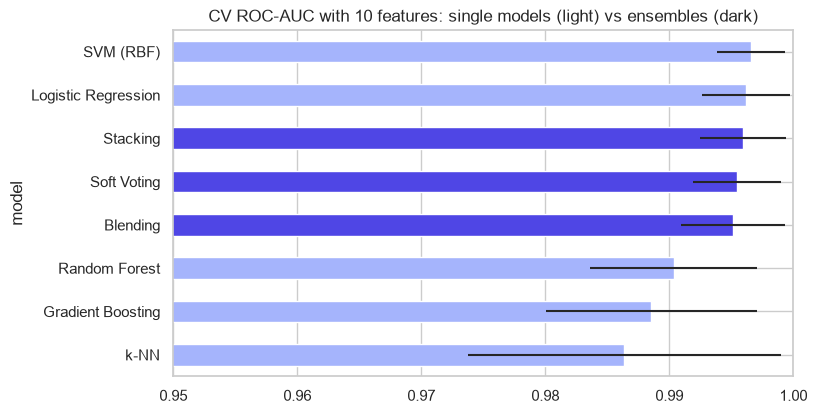

In [11]:
ens = {'Soft Voting', 'Blending', 'Stacking'}
s = res10['roc_auc'].sort_values()
ax = s.plot.barh(figsize=(8, 4.5), color=['#4f46e5' if m in ens else '#a5b4fc' for m in s.index], xerr=res10.loc[s.index, 'roc_auc_std'])
ax.set_xlim(0.95, 1.0); ax.set_title('CV ROC-AUC with 10 features: single models (light) vs ensembles (dark)');

With 10 features the picture is the same: the best approaches are within noise of each other, and stacking is among the top with the best recall for malignant tumours. Stacking is the final model: it is robust (no single model's weakness dominates) and its meta-model shows how the base models are combined.

## 5. Final check on the test set

In [12]:
models = build_models()
test = {}
for name, m in models.items():
    m.fit(X_train[features], y_train)
    test[name] = roc_auc_score(y_test, m.predict_proba(X_test[features])[:, 1])
pd.Series(test, name='test ROC-AUC').sort_values(ascending=False).round(4)

Soft Voting            0.9964
Blending               0.9960
Stacking               0.9960
Logistic Regression    0.9957
SVM (RBF)              0.9947
Random Forest          0.9947
Gradient Boosting      0.9924
k-NN                   0.9788
Name: test ROC-AUC, dtype: float64

              precision    recall  f1-score   support

      benign      0.960     1.000     0.980        72
   malignant      1.000     0.929     0.963        42

    accuracy                          0.974       114
   macro avg      0.980     0.964     0.971       114
weighted avg      0.975     0.974     0.973       114



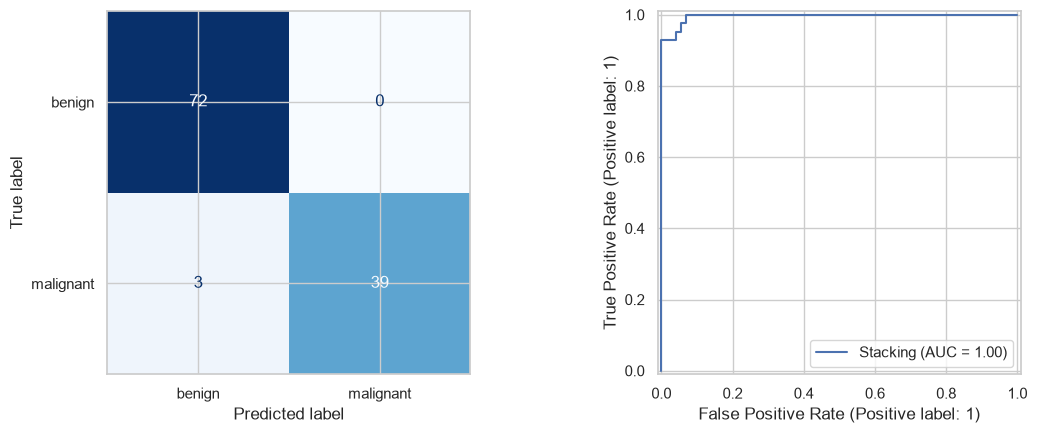

In [13]:
stack = models['Stacking']
proba = stack.predict_proba(X_test[features])[:, 1]
print(classification_report(y_test, proba >= 0.5, target_names=['benign', 'malignant'], digits=3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, proba >= 0.5, display_labels=['benign', 'malignant'], cmap='Blues', colorbar=False, ax=axes[0])
RocCurveDisplay.from_predictions(y_test, proba, name='Stacking', ax=axes[1])
plt.tight_layout()

### What the stacker learned

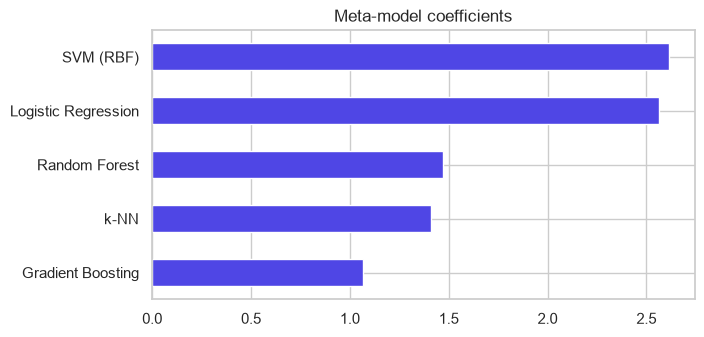

In [14]:
meta = stack[-1].final_estimator_
pd.Series(meta.coef_[0], index=[names[n] for n, _ in stack[-1].estimators]).sort_values().plot.barh(
    figsize=(7, 3.5), color='#4f46e5', title='Meta-model coefficients');

### Threshold for screening
In a screening setting a missed malignant case is far worse than a false alarm, so a lower threshold can be used:

In [15]:
from sklearn.metrics import precision_score, recall_score
pd.DataFrame([{'threshold': t, 'recall (malignant)': recall_score(y_test, proba >= t), 'precision': precision_score(y_test, proba >= t)}
              for t in [0.2, 0.3, 0.5, 0.7]]).round(3)

,threshold,recall (malignant),precision
0,0.2,0.929,0.951
1,0.3,0.929,1.000
2,0.5,0.929,1.000
3,0.7,0.929,1.000


Lowering the threshold does not recover the 3 missed malignant tumours: the model gives them low probabilities, so they look benign by these 10 measurements. A real screening tool would need more information — another reason this is only an educational demo.

## 6. Conclusions
- On this well-separated dataset single linear models are already near-perfect (ROC-AUC ≈ 0.996); ensembles match them but cannot add much — the gains are within cross-validation noise.
- Ensembles are most useful when the base models are diverse; here tree and linear models disagree the most.
- Stacking learns the combination weights from out-of-fold predictions; blending does the same with a single hold-out split, which wastes data on a small dataset and makes it slightly less stable.
- 10 well-chosen measurements keep essentially all of the accuracy of the 30-feature model.

The production version is in `train.py`; the stacking pipeline is exported to ONNX for the web demo. *Not medical advice.*